In [1]:
pip install segmentation-models

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 2.6 MB/s eta 0:00:00


In [2]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"

from tensorflow import keras
import segmentation_models as sm

Segmentation Models: using `tf.keras` framework.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1000
1000
training size is 700
valid size is 200
testing size is 100


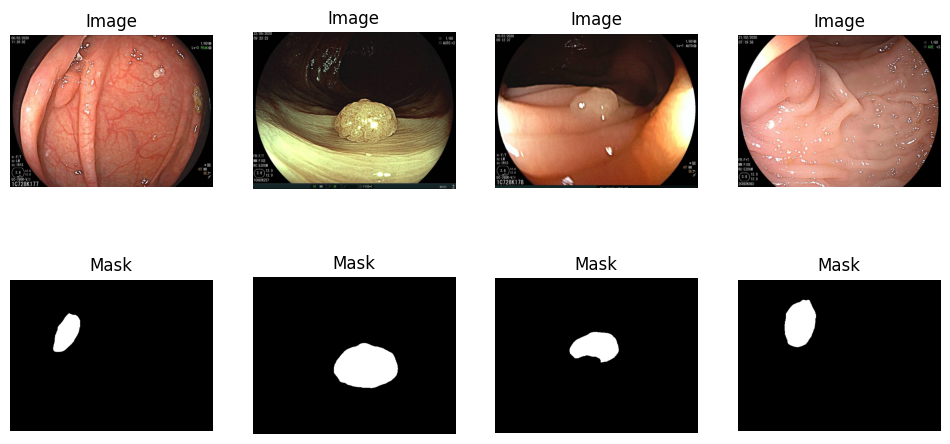

85521592/85521592 [==============================] - 0s 0us/step
Epoch 1/25
88/88 [==============================] - ETA: 0s - loss: 0.4872 - acc: 0.8571 - recall: 0.6029 - precision: 0.2147 - iou: 0.0815

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


88/88 [==============================] - 336s 3s/step - loss: 0.4872 - acc: 0.8571 - recall: 0.6029 - precision: 0.2147 - iou: 0.0815 - val_loss: 0.5199 - val_acc: 0.9397 - val_recall: 2.5381e-05 - val_precision: 0.0084 - val_iou: 0.0524 - lr: 1.0000e-04
Epoch 2/25
88/88 [==============================] - 31s 351ms/step - loss: 0.2702 - acc: 0.9698 - recall: 0.6413 - precision: 0.7831 - iou: 0.1296 - val_loss: 0.3372 - val_acc: 0.9399 - val_recall: 0.0000e+00 - val_precision: 0.0000e+00 - val_iou: 0.0477 - lr: 1.0000e-04
Epoch 3/25
88/88 [==============================] - 31s 359ms/step - loss: 0.1899 - acc: 0.9790 - recall: 0.7681 - precision: 0.8542 - iou: 0.1854 - val_loss: 0.2744 - val_acc: 0.9399 - val_recall: 0.0000e+00 - val_precision: 0.0000e+00 - val_iou: 0.0407 - lr: 1.0000e-04
Epoch 4/25
88/88 [==============================] - 31s 356ms/step - loss: 0.1407 - acc: 0.9837 - recall: 0.8264 - precision: 0.8910 - iou: 0.2463 - val_loss: 0.2475 - val_acc: 0.9399 - val_recall: 3.5

In [4]:
import os
import numpy as np
import cv2
from glob import glob
import tensorflow as tf
from sklearn.model_selection import train_test_split

def load_data(path):
    test_split = 0.1
    valid_split = 0.2
    images = sorted(glob(os.path.join(path, "images/*")))
    masks = sorted(glob(os.path.join(path, "masks/*")))
    print(len(images))
    print(len(masks))
    total_size = len(images)
    valid_size = int(valid_split * total_size)
    test_size = int(test_split * total_size)

    train_x, valid_x = train_test_split(images, test_size=valid_size, random_state=42)
    train_y, valid_y = train_test_split(masks, test_size=valid_size, random_state=42)

    train_x, test_x = train_test_split(train_x, test_size=test_size, random_state=42)
    train_y, test_y = train_test_split(train_y, test_size=test_size, random_state=42)

    return (train_x, train_y), (valid_x, valid_y), (test_x, test_y)




def read_image(path):
    path = path.decode()
    x = cv2.imread(path, cv2.IMREAD_COLOR)

    if x is None:
        raise FileNotFoundError(f"Could not read image from: {path}")


    x = cv2.resize(x, (256, 256))
    x = x / 255.0
    return x


def read_mask(path):
    path = path.decode()
    x = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if x is None:
        raise FileNotFoundError(f"Could not read mask from: {path}")

    x = cv2.resize(x, (256, 256))
    x = x / 255.0
    x = np.expand_dims(x, axis=-1)
    return x


def tf_parse(x, y):
    def _parse(x, y):
        x = read_image(x)
        y = read_mask(y)
        return x, y

    x, y = tf.numpy_function(_parse, [x, y], [tf.float64, tf.float64])
    x.set_shape([256, 256, 3])
    y.set_shape([256, 256, 1])
    return x, y

def tf_dataset(x, y, batch=8):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    dataset = dataset.map(tf_parse)
    dataset = dataset.batch(batch)
    dataset = dataset.repeat()
    return dataset

import matplotlib.pyplot as plt

import os
import numpy as np
import cv2
from glob import glob
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger, TensorBoard


def iou(y_true, y_pred):
    def f(y_true, y_pred):
        intersection = (y_true * y_pred).sum()
        union = y_true.sum() + y_pred.sum() - intersection
        x = (intersection + 1e-15) / (union + 1e-15)
        x = x.astype(np.float32)
        return x
    return tf.numpy_function(f, [y_true, y_pred], tf.float32)

if __name__ == "__main__":
    # Load data
    path = r"/content/drive/MyDrive/1ST DATASET"
    (train_x, train_y), (valid_x, valid_y), (test_x, test_y) = load_data(path)
    print(f"training size is {len(train_x)}")
    print(f"valid size is {len(valid_x)}")
    print(f"testing size is {len(test_x)}")

    # Load and preprocess some images and masks for display
    sample_images = train_x[:4] + valid_x[:4]  # 4 training and 4 validation images
    sample_masks = train_y[:4] + valid_y[:4]  # 4 training and 4 validation masks

    plt.figure(figsize=(12, 9))

    for i in range(8):
        plt.subplot(3, 4, i + 1)
        if i < 4:
            img = cv2.imread(sample_images[i])
        else:
            img = cv2.imread(sample_masks[i - 4])
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if i < 4:
            plt.title("Image")
        else:
            plt.title("Mask")
        plt.axis("off")

    plt.show()



    # Hyperparameters
    batch = 8
    lr = 1e-4
    epochs = 20


    train_dataset = tf_dataset(train_x, train_y, batch=batch)
    valid_dataset = tf_dataset(valid_x, valid_y, batch=batch)


    # Create the U-Net model
    BACKBONE = 'resnet34'  # You can change this to your desired backbone
    model = sm.Unet(BACKBONE, encoder_weights='imagenet', activation='sigmoid', classes=1, input_shape=(256, 256, 3))
    opt = tf.keras.optimizers.Adam(lr)
    metrics = ["acc", tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), iou]
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=metrics)

    callbacks = [
        ModelCheckpoint("uunet.h5"),
        ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=4),
        CSVLogger("data.csv"),
        TensorBoard(),
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=False,min_delta = 0)
    ]

    train_steps = len(train_x)//batch
    valid_steps = len(valid_x)//batch

    if len(train_x) % batch != 0:
        train_steps += 1
    if len(valid_x) % batch != 0:
        valid_steps += 1

    history=model.fit(train_dataset,
        validation_data=valid_dataset,
        epochs=100,
        steps_per_epoch=train_steps,
        validation_steps=valid_steps,
        callbacks=callbacks)




  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 2s 2s/step


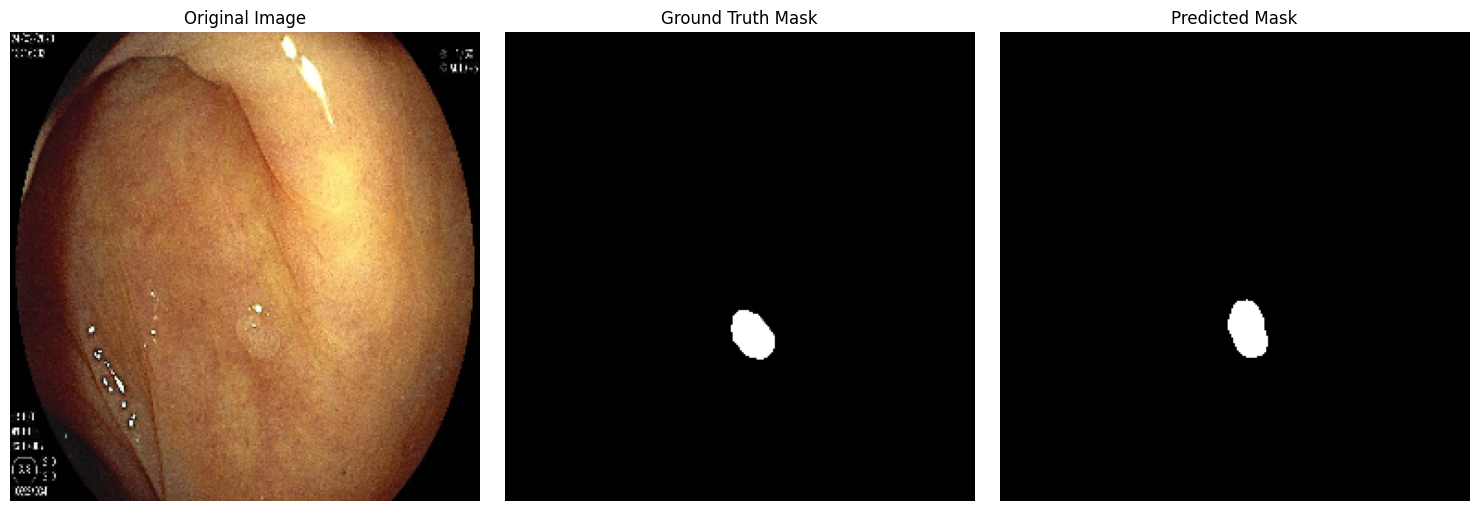

  1%|          | 1/100 [00:02<04:51,  2.94s/it]

1/1 [==============================] - 0s 31ms/step


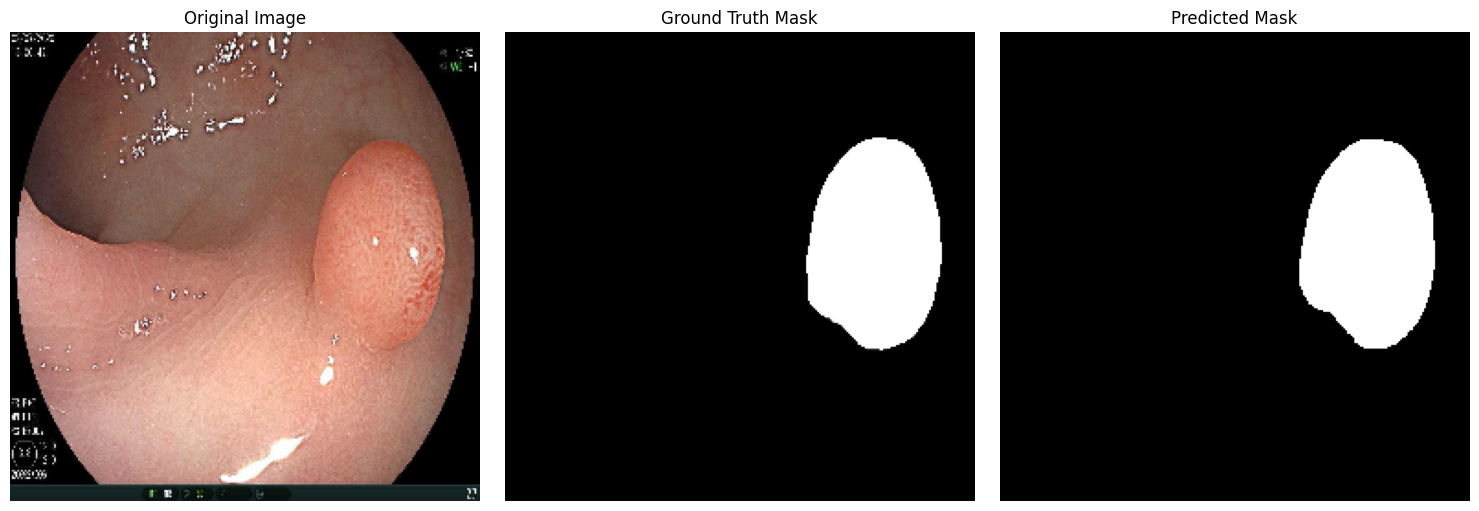

  2%|▏         | 2/100 [00:03<02:52,  1.76s/it]

1/1 [==============================] - 0s 22ms/step


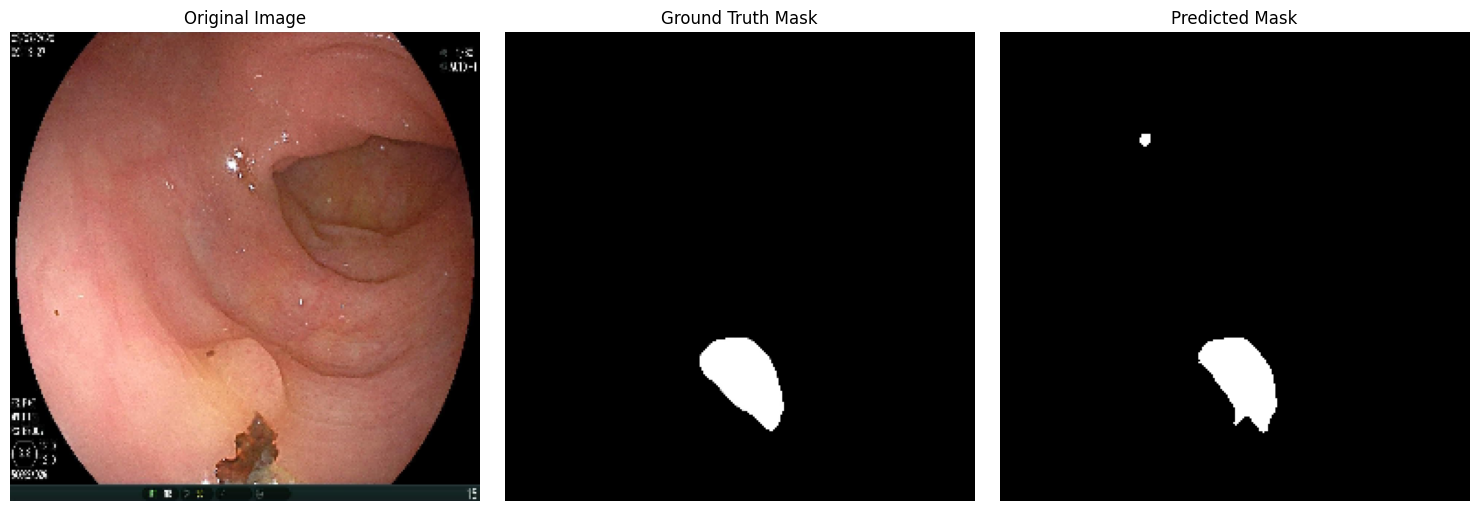

  3%|▎         | 3/100 [00:04<02:09,  1.33s/it]

1/1 [==============================] - 0s 31ms/step


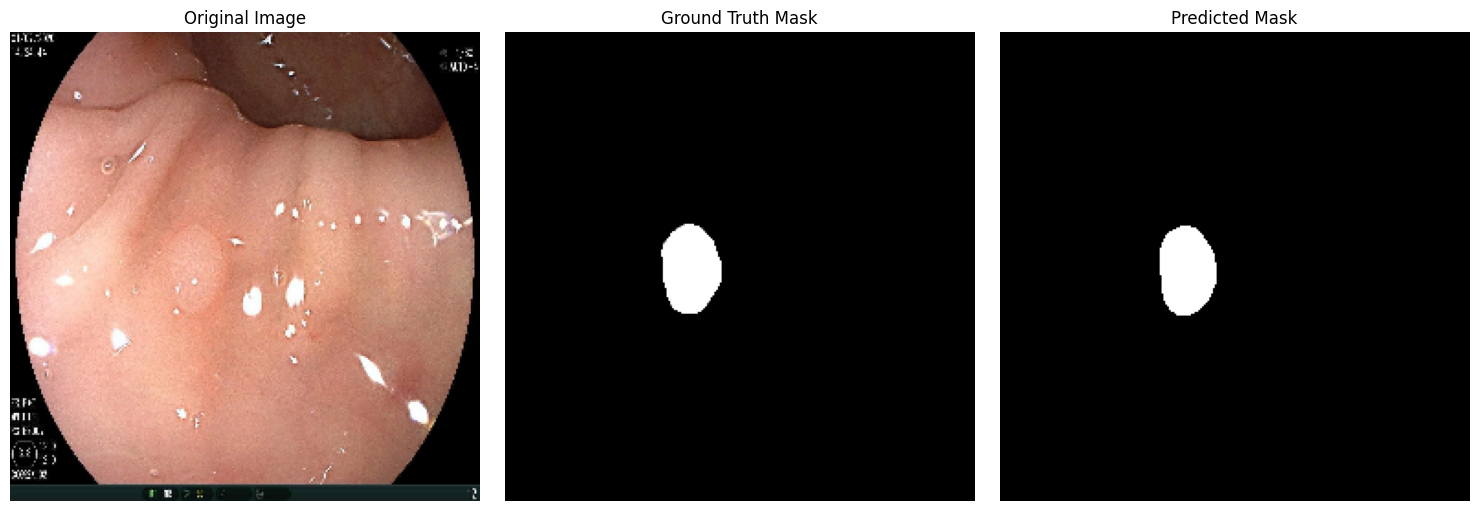

  4%|▍         | 4/100 [00:05<01:48,  1.13s/it]

1/1 [==============================] - 0s 23ms/step


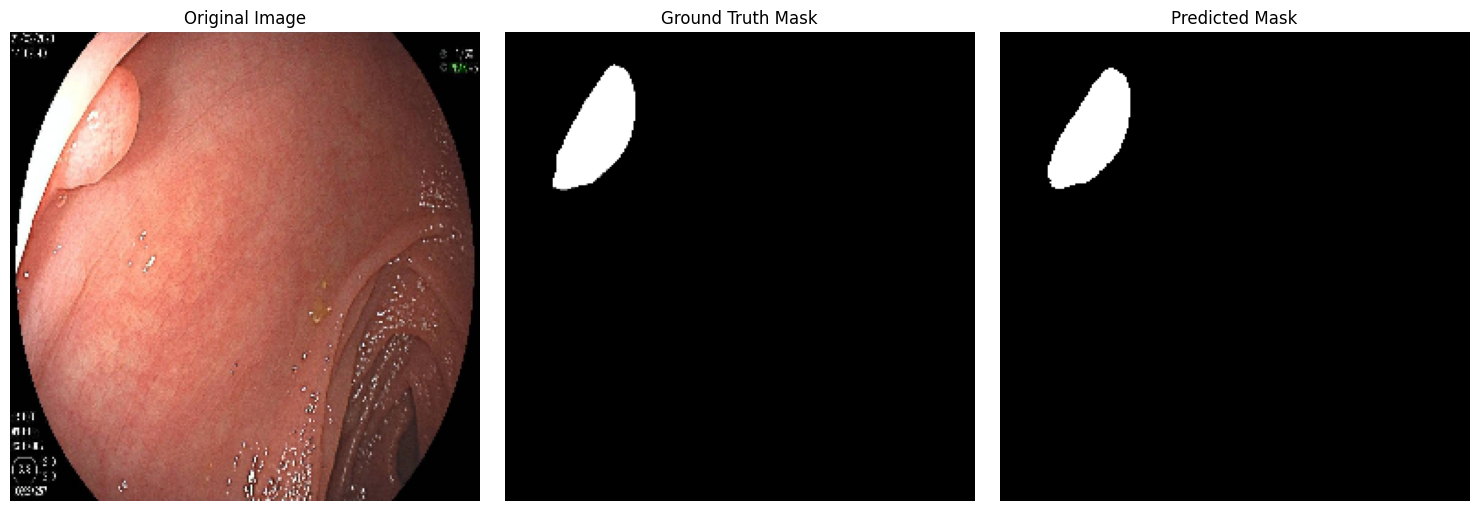

  5%|▌         | 5/100 [00:06<01:36,  1.01s/it]

1/1 [==============================] - 0s 22ms/step


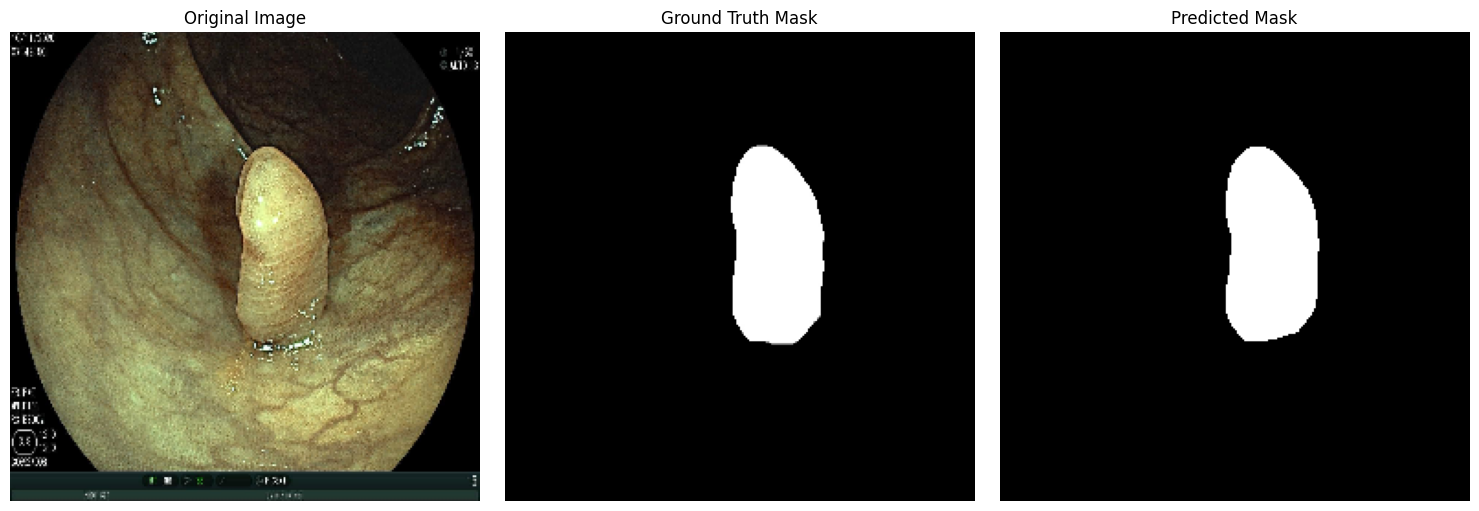

  6%|▌         | 6/100 [00:07<01:31,  1.03it/s]

1/1 [==============================] - 0s 26ms/step


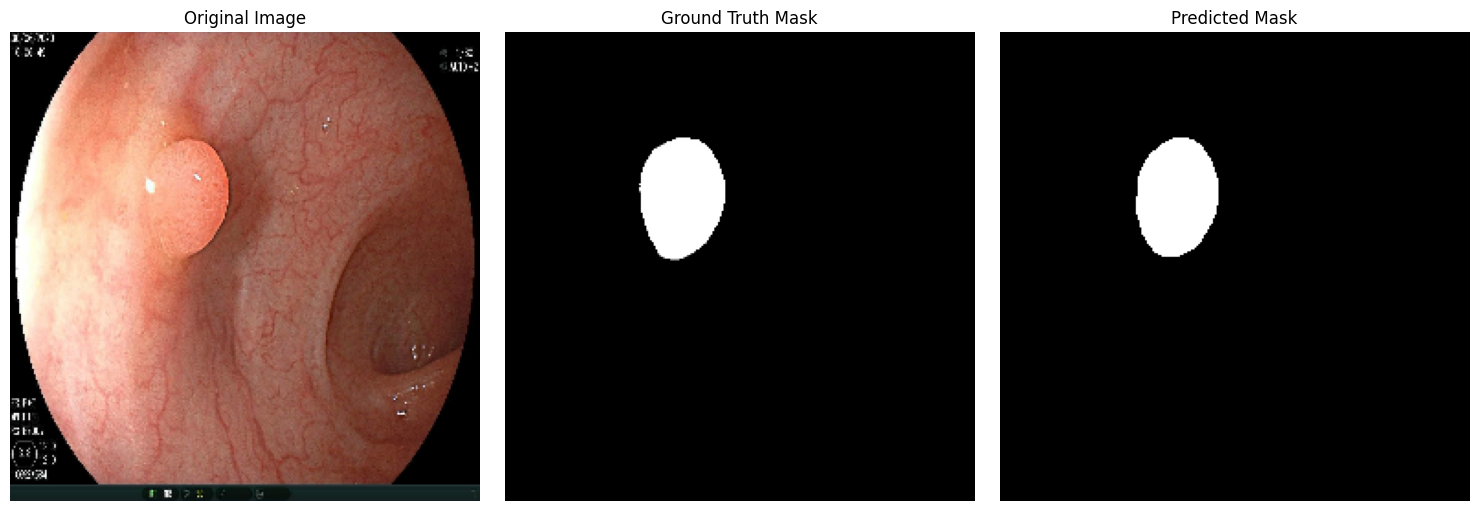

  7%|▋         | 7/100 [00:08<01:29,  1.04it/s]

1/1 [==============================] - 0s 32ms/step


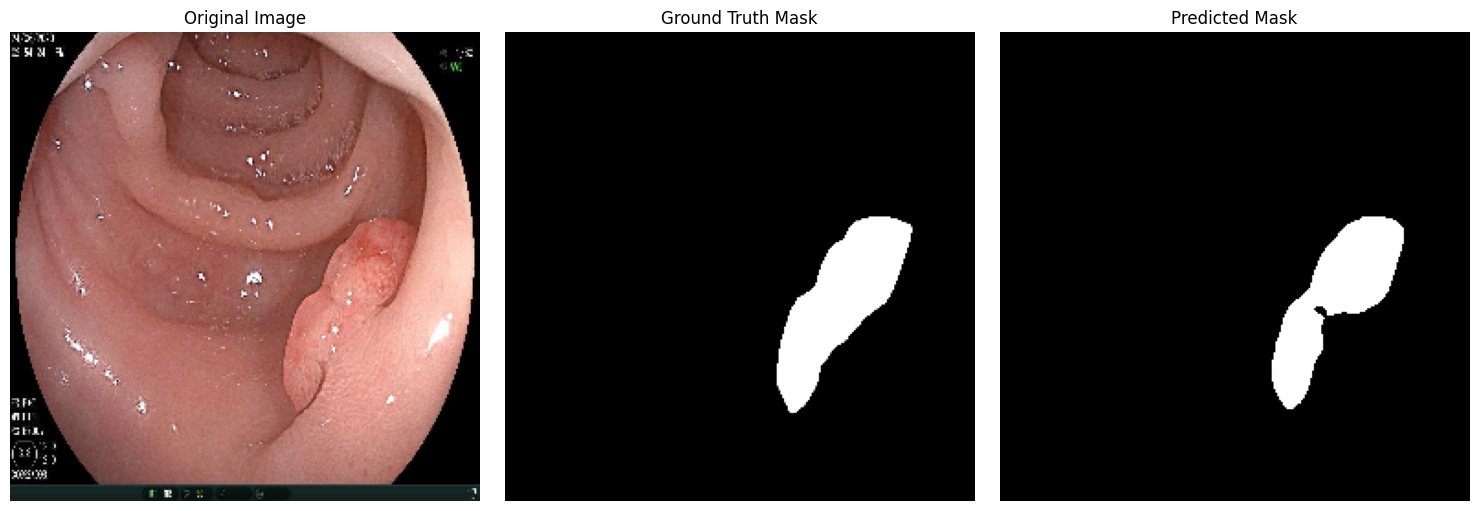

  8%|▊         | 8/100 [00:09<01:31,  1.01it/s]

1/1 [==============================] - 0s 34ms/step


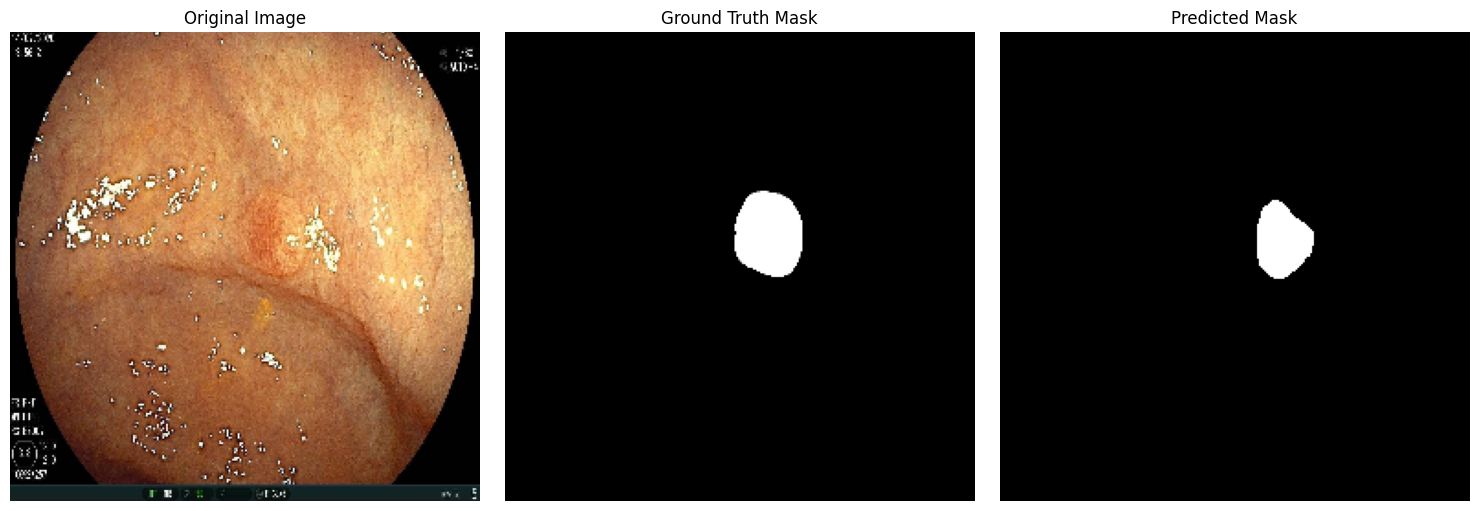

  9%|▉         | 9/100 [00:10<01:37,  1.08s/it]

1/1 [==============================] - 0s 35ms/step


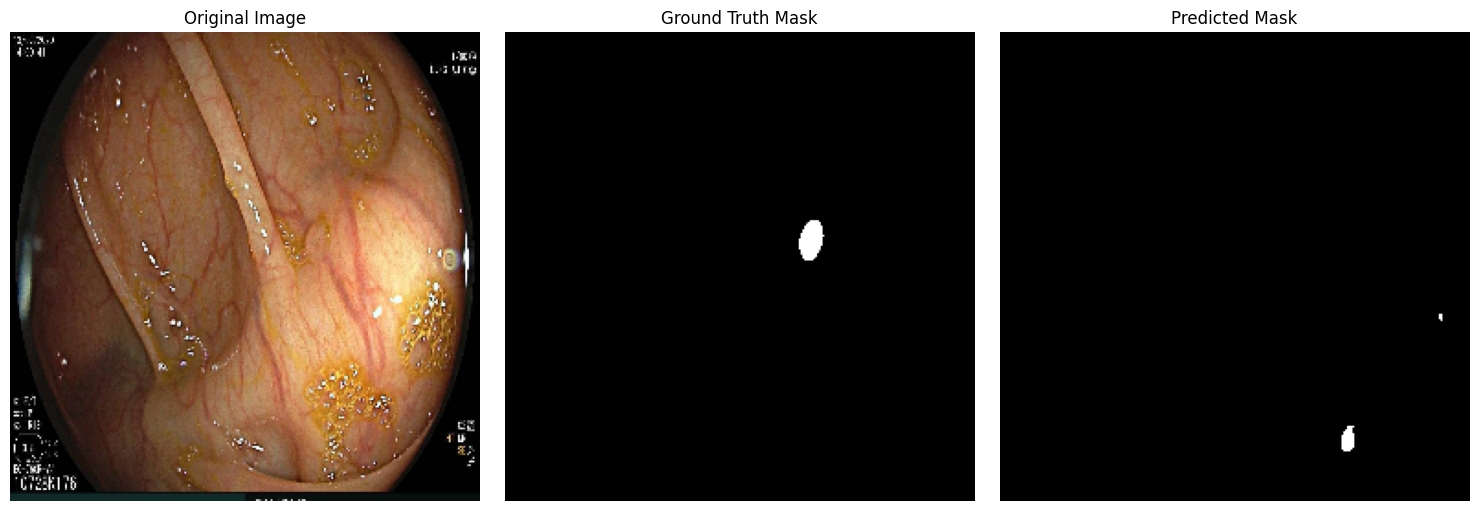

 10%|█         | 10/100 [00:11<01:45,  1.17s/it]


In [5]:
import os
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import CustomObjectScope
from tqdm import tqdm


def read_image(path):
    x = cv2.imread(path, cv2.IMREAD_COLOR)
    x = cv2.resize(x, (256, 256))
    x = x/255.0
    return x

def read_mask(path):
    x = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    x = cv2.resize(x, (256, 256))
    x = np.expand_dims(x, axis=-1)
    return x

def mask_parse(mask):
    mask = np.squeeze(mask)
    mask = [mask, mask, mask]
    mask = np.transpose(mask, (1, 2, 0))
    return mask

if True:

    with CustomObjectScope({'iou': iou}):
        model = tf.keras.models.load_model("uunet.h5")

    for i, (x, y) in tqdm(enumerate(zip(test_x[:10], test_y[:10])), total=len(test_x)):
        x = read_image(x)
        y = read_mask(y)
        y_pred = model.predict(np.expand_dims(x, axis=0))[0] > 0.5
        h, w, _ = x.shape
        white_line = np.ones((h, 10, 3)) * 255.0

        # Prepare images for visualization
        original_image = x * 255.0
        ground_truth_mask = mask_parse(y)
        predicted_mask = mask_parse(y_pred) * 255.0

        all_images = [original_image.astype(np.uint8), white_line, ground_truth_mask, white_line, predicted_mask]

        # Display the images using matplotlib
        plt.figure(figsize=(15, 5))
        plt.subplot(1, 3, 1)
        plt.imshow(cv2.cvtColor(all_images[0], cv2.COLOR_BGR2RGB))  # Convert to RGB for correct display
        plt.title('Original Image')
        plt.axis('off')

        plt.subplot(1, 3, 2)
        plt.imshow(ground_truth_mask)
        plt.title('Ground Truth Mask')
        plt.axis('off')

        plt.subplot(1, 3, 3)
        plt.imshow(predicted_mask.astype(np.uint8))
        plt.title('Predicted Mask')
        plt.axis('off')

        plt.tight_layout()
        plt.show()

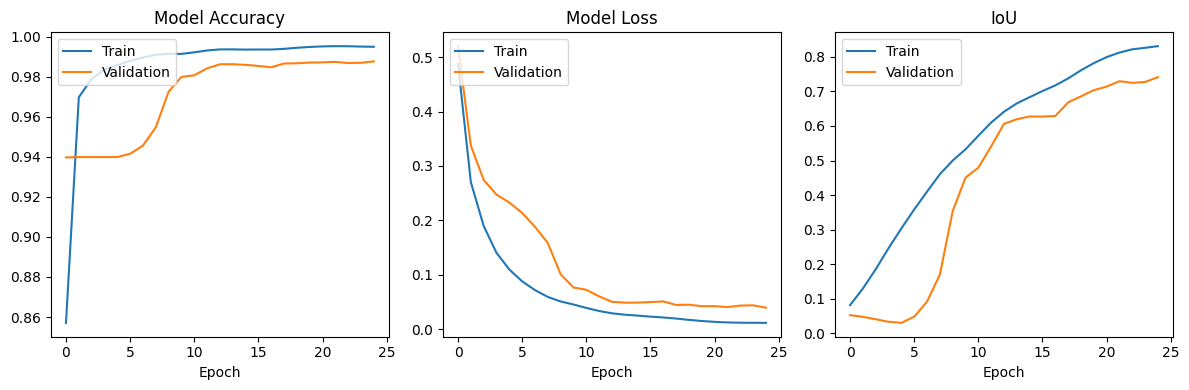

In [6]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    # Plot training & validation accuracy values
    plt.figure(figsize=(12, 4))
    plt.subplot(131)
    plt.plot(history.history['acc'])
    plt.plot(history.history['val_acc'])
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation loss values
    plt.subplot(132)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation IoU (Custom Metric)
    plt.subplot(133)
    plt.plot(history.history['iou'])
    plt.plot(history.history['val_iou'])
    plt.title('IoU')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Assuming you have already compiled and trained your model

# Plot the training history
plot_training_history(history)


In [7]:
import numpy as np
from sklearn.metrics import fowlkes_mallows_score
from tqdm import tqdm
from skimage.measure import shannon_entropy

# Function to calculate Dice Coefficient (F1 score)
def dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred)
    dice = (2.0 * intersection) / (union + 1e-7)
    return dice

# Function to calculate Intersection over Union (IoU)
def intersection_over_union(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    iou = (intersection + 1e-7) / (union + 1e-7)
    return iou

# Function to calculate Sørensen-Dice Coefficient (SM)
def sorensen_dice_coefficient(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    denominator = np.sum(y_true) + np.sum(y_pred)
    sm = (2.0 * intersection) / (denominator + 1e-7)
    return sm
def jaccard_index(y_true, y_pred):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(np.maximum(y_true, y_pred))  # Union is the maximum of the two masks
    jaccard = intersection / (union + 1e-7)  # Adding a small constant to avoid division by zero
    return jaccard



# Load the model
with CustomObjectScope({'iou': iou}):
    model = tf.keras.models.load_model(r"uunet.h5")

# Initialize lists to store individual metric values
dice_scores = []
iou_scores = []
fm_scores = []
sm_scores = []
jaccard_scores = []

# Iterate through test images
for i, (x, y) in tqdm(enumerate(zip(test_x, test_y)), total=len(test_x)):
    x = read_image(x)
    y_true = read_mask(y)
    y_pred = model.predict(np.expand_dims(x, axis=0))[0] > 0.5

    # Convert the masks to binary format for metrics calculation
    true_mask_binary = (y_true.squeeze() > 0.5).astype(np.uint8)
    predicted_mask_binary = (y_pred.squeeze() > 0.5).astype(np.uint8)

    # Calculate metrics for the current image
    dice_scores.append(dice_coefficient(true_mask_binary, predicted_mask_binary))
    iou_scores.append(intersection_over_union(true_mask_binary, predicted_mask_binary))

    # Flatten the masks for FM calculation
    true_mask_flat = true_mask_binary.flatten()
    predicted_mask_flat = predicted_mask_binary.flatten()

    # Calculate Fowlkes-Mallows Index (FM)
    fm_scores.append(fowlkes_mallows_score(true_mask_flat, predicted_mask_flat))

    # Calculate Sørensen-Dice Coefficient (SM)
    sm_scores.append(sorensen_dice_coefficient(true_mask_binary, predicted_mask_binary))

    # Calculate Mean Absolute Error (MAE)
    jaccard_scores.append(jaccard_index(y_true, y_pred))

    # Calculate Entropy (EM)

# Calculate the mean of each metric
mean_dice = np.mean(dice_scores)
mean_iou = np.mean(iou_scores)
mean_fm = np.mean(fm_scores)
mean_sm = np.mean(sm_scores)
mean_js = np.mean(jaccard_scores)

# Print the mean metrics
print("Mean Dice Coefficient:", mean_dice)
print("Mean Intersection over Union:", mean_iou)
print("Mean Fowlkes-Mallows Index (FM):", mean_fm)
print("Mean Sørensen-Dice Coefficient (SM):", mean_sm)
print("Mean Jaccard Index:", mean_js)

  0%|          | 0/100 [00:00<?, ?it/s]

1/1 [==============================] - 1s 770ms/step


  1%|          | 1/100 [00:00<01:26,  1.14it/s]

1/1 [==============================] - 0s 26ms/step


  2%|▏         | 2/100 [00:00<00:41,  2.34it/s]

1/1 [==============================] - 0s 25ms/step


... (192 outputs left out)

 99%|█████████▉| 99/100 [00:37<00:00,  2.52it/s]

1/1 [==============================] - 0s 24ms/step


100%|██████████| 100/100 [00:38<00:00,  2.62it/s]

Mean Dice Coefficient: 0.7866477913409501
Mean Intersection over Union: 0.7015618007508944
Mean Fowlkes-Mallows Index (FM): 0.9888435056614333
Mean Sørensen-Dice Coefficient (SM): 0.7866477913409501
Mean Jaccard Index: 0.7721199781656302
